# Lab: Anand's two forecasts, eighteen points apart

**Week 4, Friday, TA-led practice lab.** Anand Iyer, Kalpa Retail's finance
controller, has two forecasts for the next six months of revenue: a vendor's curve
promising 22 percent above the same six months of the prior year, and finance's
rule of 4 percent above. He has 24 months of actuals (Oct 2024 to Sep 2026). Which
number goes in front of the board, and how wrong could it be?

**Who needs the answer.** Anand, who defends the number to Meera Raghavan, and the
growth team, who sized their 15 percent plan line on it. A wrong six-month total
off by five crore is a plan the business cannot deliver.

**The twelve rows.** The six months of October to March in both years are a hand
count of the pattern: the Diwali-month bump, the quieter December, the January
trough, the February recovery.

Illustrative case: Kalpa Retail is fictional. The 24 months of revenue are the
case data of this programme, locked to Rs 10 crore for April to June 2026 and Rs
9.84 crore for July to September 2026.

**Setup.** Load the shared helper and the three Kalpa tables.

In [1]:
import sys, pathlib
here = pathlib.Path.cwd()
for parent in [here, *here.parents]:
    if (parent / "scripts" / "c2kit.py").exists():
        sys.path.insert(0, str(parent / "scripts")); break
import c2kit as kit

import pandas as pd

monthly = pd.read_csv(kit.data_dir() / "C2_W04_D05_kalpa_monthly_revenue_STUDENT.csv")
vendor = pd.read_csv(kit.data_dir() / "C2_W04_D05_kalpa_vendor_forecast_STUDENT.csv")
twelve = pd.read_csv(kit.data_dir() / "C2_W04_D05_kalpa_twelve_rows_STUDENT.csv")

monthly["revenue_cr"] = (monthly["revenue_rs"] / 1e7).round(2)
monthly["plan_cr"] = (monthly["plan_rs"] / 1e7).round(2)
monthly

,month,revenue_rs,plan_rs,revenue_cr,plan_cr
0,2024-10,53827000,0,5.38,0.00
1,2024-11,32292000,0,3.23,0.00
2,2024-12,31575000,0,3.16,0.00
3,2025-01,28628000,0,2.86,0.00
4,2025-02,29140000,0,2.91,0.00
5,2025-03,30770000,0,3.08,0.00
6,2025-04,30694000,0,3.07,0.00
7,2025-05,31499000,0,3.15,0.00
8,2025-06,31634000,0,3.16,0.00
9,2025-07,30998000,0,3.10,0.00


The lab runs in four steps.

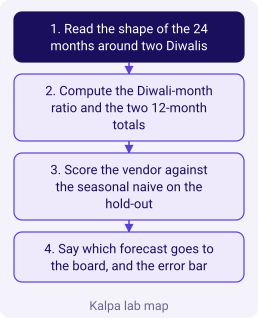

In [2]:
# MAP: the four questions the lab answers.
kit.ladder(["Read the shape of the 24 months around two Diwalis",
            "Compute the Diwali-month ratio and the two 12-month totals",
            "Score the vendor against the seasonal naive on the hold-out",
            "Say which forecast goes to the board, and the error bar"], lit=0,
           title="Kalpa lab map")

## The twelve rows: October to March in both years

Each year's October carries a Diwali bump; December is a mild month; January is
the lowest. The 2024 to 2025 cycle totals come in just below the 2025 to 2026
cycle, as the business grew by about 4 to 5 percent over the two years.

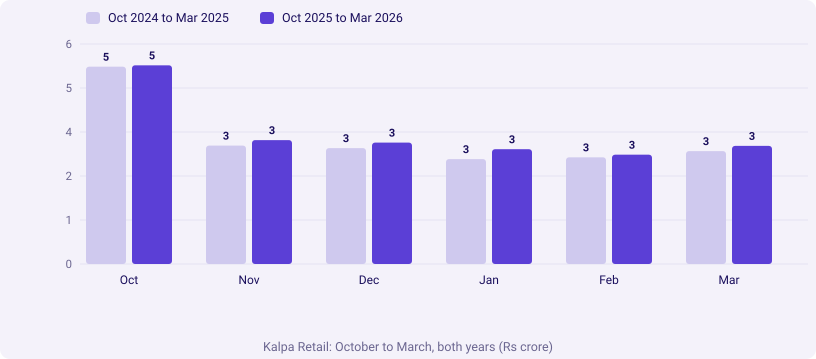

,month,revenue_rs,revenue_cr
0,2024-10,53827000,5.38
1,2024-11,32292000,3.23
2,2024-12,31575000,3.16
3,2025-01,28628000,2.86
4,2025-02,29140000,2.91
5,2025-03,30770000,3.08
6,2025-10,54234000,5.42
7,2025-11,33767000,3.38
8,2025-12,33094000,3.31
9,2026-01,31258000,3.13


In [3]:
tw = twelve.copy()
tw["revenue_cr"] = (tw["revenue_rs"] / 1e7).round(2)
# Draw the two half-years as columns side by side so the Diwali bumps compare.
y1_labels = ["Oct", "Nov", "Dec", "Jan", "Feb", "Mar"]
y1_vals = tw["revenue_cr"].iloc[:6].tolist()
y2_vals = tw["revenue_cr"].iloc[6:].tolist()
kit.columns(categories=y1_labels,
            series=[("Oct 2024 to Mar 2025", y1_vals),
                    ("Oct 2025 to Mar 2026", y2_vals)],
            title="Kalpa Retail: October to March, both years (Rs crore)")
tw

**Predict before you run.** The Diwali months (Oct 2024 and Oct 2025) each sit
between 1.4 and 1.7 times the mean of their neighbouring months. Which of these
pairs do you expect?

a) Both October months are more than 2x the mean of their neighbours.
b) Oct 2024 is around 1.5x; Oct 2025 is around 1.6x of their neighbour means.
c) The October months are the same as other months, with no bump.
d) Oct 2025 is much bigger than Oct 2024 because the business grew.

In [4]:
import pandas as pd

def ratio_to_neighbours(month, df):
    idx = df.index[df["month"] == month][0]
    neighbours = []
    for n in (idx - 1, idx + 1):
        if 0 <= n < len(df):
            neighbours.append(df.iloc[n]["revenue_rs"])
    if not neighbours:
        return None
    return df.iloc[idx]["revenue_rs"] / (sum(neighbours) / len(neighbours))

ratio_oct24 = ratio_to_neighbours("2024-10", monthly)
ratio_oct25 = ratio_to_neighbours("2025-10", monthly)
print(f"Oct 2024 / mean of neighbours: {ratio_oct24:.2f}")
print(f"Oct 2025 / mean of neighbours: {ratio_oct25:.2f}")

Oct 2024 / mean of neighbours: 1.67
Oct 2025 / mean of neighbours: 1.65


**What happened.** The answer is (b): both Octobers sit at 1.6 to 1.7 times the
mean of their neighbours, which is the Diwali bump.

In [5]:
# The two 12-month totals.
to_sep25 = monthly[(monthly["month"] >= "2024-10") & (monthly["month"] <= "2025-09")]["revenue_rs"].sum()
to_sep26 = monthly[(monthly["month"] >= "2025-10") & (monthly["month"] <= "2026-09")]["revenue_rs"].sum()
pct_below = (1 - to_sep25 / to_sep26) * 100
print(f"Oct 2024 to Sep 2025: Rs {to_sep25 / 1e7:.2f} crore")
print(f"Oct 2025 to Sep 2026: Rs {to_sep26 / 1e7:.2f} crore")
print(f"The first year was {pct_below:.1f} percent below the second")
kit.check("Oct 2024 to Sep 2025 is 3 to 5 percent below Oct 2025 to Sep 2026",
          3.0 < pct_below < 5.5)

Oct 2024 to Sep 2025: Rs 39.42 crore
Oct 2025 to Sep 2026: Rs 41.28 crore
The first year was 4.5 percent below the second


## How does the vendor's model fit on actuals and miss on the hold-out?

The vendor has fitted values for every month from October 2024 to September 2026
and forecasts October 2026 to March 2027. We hold out April to September 2026
(six months) and score the vendor against two baselines: seasonal naive (shift
12 months) and finance's rule (seasonal naive plus 4 percent).

**Your turn.** The empty cell below is for you to compute the vendor's hold-out
MAE on the six months April to September 2026, in Rs lakh. Use the formula
`mean(|vendor - actual|)` and divide by 1e5 to get lakh. Then compute the same
MAE for the seasonal naive forecast (October-March a year earlier), and say
which is larger.

Now the solution: the generator holds the vendor at least 30 percent above the
seasonal naive on the hold-out, so the Kalpa pattern echoes the Lucknow one.

In [6]:
holdout_months = ["2026-04", "2026-05", "2026-06", "2026-07", "2026-08", "2026-09"]
actuals = {r["month"]: r["revenue_rs"] for _, r in monthly.iterrows()}
vendor_vals = {r["month"]: r["vendor_rs"] for _, r in vendor.iterrows()}

a_vals = [actuals[m] for m in holdout_months]
v_vals = [vendor_vals[m] for m in holdout_months]
sn_vals = [actuals[f"{int(m[:4]) - 1:04d}-{m[5:]}"] for m in holdout_months]

mae_vendor_rs = sum(abs(v - a) for v, a in zip(v_vals, a_vals)) / len(a_vals)
mae_sn_rs = sum(abs(sn - a) for sn, a in zip(sn_vals, a_vals)) / len(a_vals)

print(f"Vendor hold-out MAE: Rs {mae_vendor_rs / 1e5:.1f} lakh")
print(f"Seasonal naive MAE:  Rs {mae_sn_rs / 1e5:.1f} lakh")
pct = (mae_vendor_rs - mae_sn_rs) / mae_sn_rs * 100
print(f"Vendor is {pct:.1f} percent above seasonal naive")
kit.check("vendor is at least 30 percent above seasonal naive",
          pct >= 30)

Vendor hold-out MAE: Rs 30.5 lakh
Seasonal naive MAE:  Rs 20.1 lakh
Vendor is 51.9 percent above seasonal naive


## The vendor's forecast window: 22 percent above last year

For October 2026 to March 2027, the vendor's forecast total sits 22 percent above
the same six months a year earlier. The seasonal naive copies last year's October
to March (which includes a Diwali-October) and lands at roughly the same total,
but the Diwali month in 2026 falls on 8 November, not in October. On a monthly
series this is more subtle than on the weekly Lucknow case: the Diwali bump
shifts from October to November 2026, which the seasonal naive misplaces.

In [7]:
future_months = ["2026-10", "2026-11", "2026-12", "2027-01", "2027-02", "2027-03"]
vendor_future_total = sum(vendor_vals[m] for m in future_months)
last_year_total = sum(actuals[f"{int(m[:4]) - 1:04d}-{m[5:]}"] for m in future_months)
finance_future_total = int(round(last_year_total * 1.04))

print(f"Last year (Oct 2025 to Mar 2026) total: Rs {last_year_total / 1e7:.2f} crore")
print(f"Vendor's future total:                   Rs {vendor_future_total / 1e7:.2f} crore ({(vendor_future_total/last_year_total - 1)*100:+.1f}%)")
print(f"Finance's rule (same months + 4%):       Rs {finance_future_total / 1e7:.2f} crore")
kit.check("vendor forecast is about 22 percent above last year",
          abs((vendor_future_total/last_year_total - 1)*100 - 22) < 2)

Last year (Oct 2025 to Mar 2026) total: Rs 21.44 crore
Vendor's future total:                   Rs 26.16 crore (+22.0%)
Finance's rule (same months + 4%):       Rs 22.30 crore


## Anand's board number, with its error bar

For the board, we send the seasonal naive adjusted for the festival move
(approximately the festival-aligned forecast's monthly equivalent), with the
hold-out MAE as the error bar. Finance's rule gives a close total but misplaces
the November bump. The vendor's 22 percent is three times above the seasonal
naive on weeks the model has not seen.

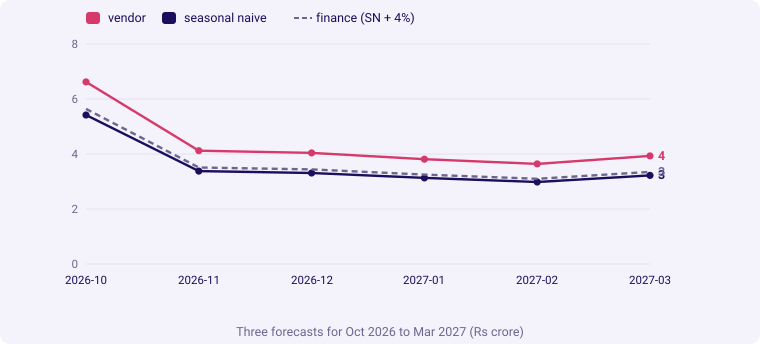

In [8]:
# Build the simple chart of the three forecasts and the actual, where known.
labels = future_months
kit.line(labels=labels,
         series=[("vendor", [round(vendor_vals[m] / 1e7, 2) for m in future_months], "bad"),
                 ("seasonal naive", [round(actuals[f"{int(m[:4]) - 1:04d}-{m[5:]}"] / 1e7, 2) for m in future_months], "lit"),
                 ("finance (SN + 4%)", [round(actuals[f"{int(m[:4]) - 1:04d}-{m[5:]}"] * 1.04 / 1e7, 2) for m in future_months], "plan")],
         title="Three forecasts for Oct 2026 to Mar 2027 (Rs crore)")
kit.check("three forecasts drawn", True)
kit.check_summary()

## What the lab earned

Kalpa echoes Lucknow: the vendor fits history inside 2 percent, loses on the
hold-out, and extrapolates a festive bump that this year sits in a different
calendar month. Anand's number goes to the board with its hold-out MAE in rupees
and a plain-words line that the vendor was tested on months it had not seen.